In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("Libraries imported successfully!")

Libraries imported successfully!


In [4]:
processed_path = "../data/processed"

customers = pd.read_csv(f"{processed_path}/customers.csv")
orders = pd.read_csv(f"{processed_path}/orders.csv")
order_items = pd.read_csv(f"{processed_path}/order_items.csv")
payments = pd.read_csv(f"{processed_path}/payments.csv")
reviews = pd.read_csv(f"{processed_path}/reviews.csv")
products = pd.read_csv(f"{processed_path}/products.csv")
sellers = pd.read_csv(f"{processed_path}/sellers.csv")
geolocation = pd.read_csv(f"{processed_path}/geolocation.csv")

print("All datasets loaded successfully!")

All datasets loaded successfully!


In [5]:
datasets = {
    "customers": customers,
    "orders": orders,
    "order_items": order_items,
    "payments": payments,
    "reviews": reviews,
    "products": products,
    "sellers": sellers,
    "geolocation": geolocation
}

for name, df in datasets.items():

    print(f"\n{name.upper()}")
    print("Rows:", df.shape[0])
    print("Columns:", df.shape[1])


CUSTOMERS
Rows: 99441
Columns: 5

ORDERS
Rows: 99441
Columns: 8

ORDER_ITEMS
Rows: 112650
Columns: 7

PAYMENTS
Rows: 103886
Columns: 5

REVIEWS
Rows: 99224
Columns: 7

PRODUCTS
Rows: 32951
Columns: 9

SELLERS
Rows: 3095
Columns: 4

GEOLOCATION
Rows: 19015
Columns: 5


In [6]:
for name, df in datasets.items():

    numerical = df.select_dtypes(include=["int64", "float64"]).columns

    categorical = df.select_dtypes(include=["object", "category"]).columns

    print(f"\n{name.upper()}")

    print("Numerical Columns:")
    print(list(numerical))

    print("Categorical Columns:")
    print(list(categorical))


CUSTOMERS
Numerical Columns:
['customer_zip_code_prefix']
Categorical Columns:
['customer_id', 'customer_unique_id', 'customer_city', 'customer_state']

ORDERS
Numerical Columns:
[]
Categorical Columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

ORDER_ITEMS
Numerical Columns:
['order_item_id', 'price', 'freight_value']
Categorical Columns:
['order_id', 'product_id', 'seller_id', 'shipping_limit_date']

PAYMENTS
Numerical Columns:
['payment_sequential', 'payment_installments', 'payment_value']
Categorical Columns:
['order_id', 'payment_type']

REVIEWS
Numerical Columns:
['review_score']
Categorical Columns:
['review_id', 'order_id', 'review_comment_title', 'review_comment_message', 'review_creation_date', 'review_answer_timestamp']

PRODUCTS
Numerical Columns:
['product_name_lenght', 'product_description_lenght', 'product_photos_qty', 'pro

C:\Users\Admin\AppData\Local\Temp\ipykernel_12100\2743173753.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include=["object", "category"]).columns
C:\Users\Admin\AppData\Local\Temp\ipykernel_12100\2743173753.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/d

In [7]:
orders["order_status"].value_counts()

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

In [8]:
status_percentage = (
    orders["order_status"]
    .value_counts(normalize=True) * 100
)

print(status_percentage.round(2))

order_status
delivered      97.02
shipped         1.11
canceled        0.63
unavailable     0.61
invoiced        0.32
processing      0.30
created         0.01
approved        0.00
Name: proportion, dtype: float64


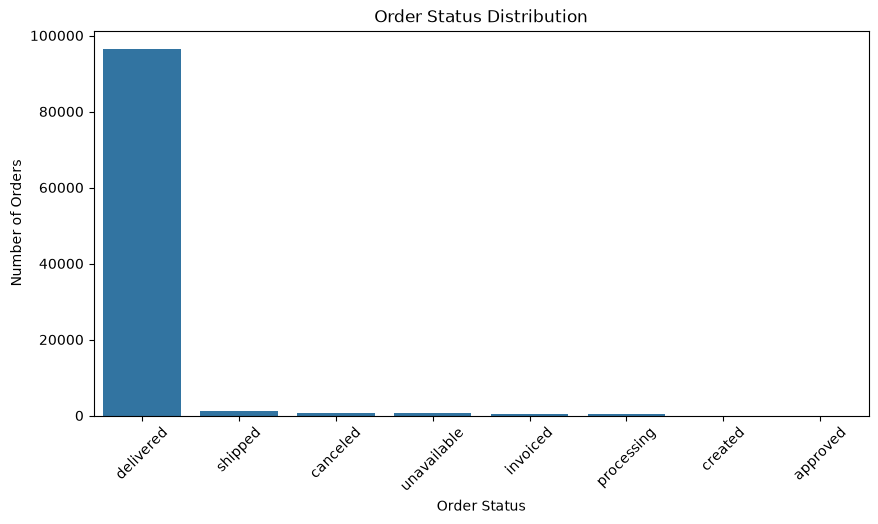

In [9]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=orders,
    x="order_status",
    order=orders["order_status"].value_counts().index
)

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()

Bi-varient analysis


In [10]:
payments["payment_value"].median()

np.float64(100.0)

In [14]:
payment = payments["payment_value"]

In [15]:
print("Mean:", payment.mean())

print("Median:", payment.median())

print("Mode:", payment.mode().tolist())

print("Variance:", payment.var())

print("Standard Deviation:", payment.std())

print("Minimum:", payment.min())

print("Maximum:", payment.max())

Mean: 154.10038041699556
Median: 100.0
Mode: [50.0]
Variance: 47303.66781639279
Standard Deviation: 217.49406386472435
Minimum: 0.0
Maximum: 13664.08


In [16]:
payments["payment_value"].describe()

count    103886.000000
mean        154.100380
std         217.494064
min           0.000000
25%          56.790000
50%         100.000000
75%         171.837500
max       13664.080000
Name: payment_value, dtype: float64

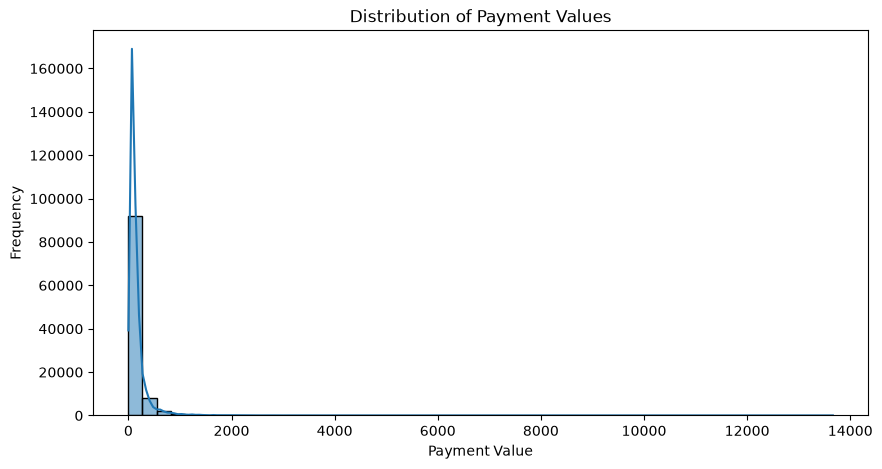

In [17]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=payments,
    x="payment_value",
    bins=50,
    kde=True
)

plt.title("Distribution of Payment Values")
plt.xlabel("Payment Value")
plt.ylabel("Frequency")

plt.show()

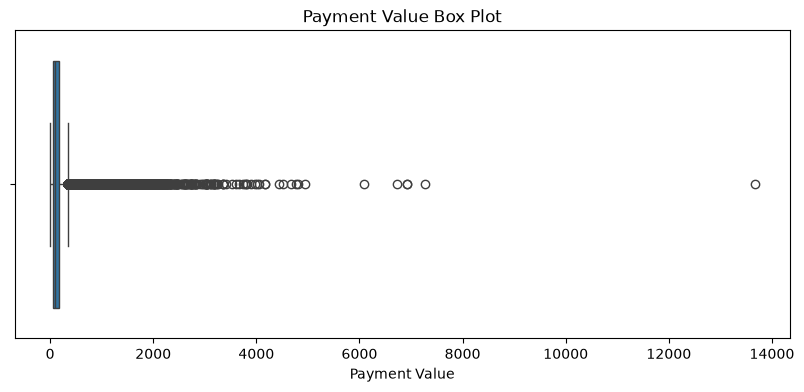

In [18]:
plt.figure(figsize=(10, 4))

sns.boxplot(x=payments["payment_value"])

plt.title("Payment Value Box Plot")
plt.xlabel("Payment Value")

plt.show()

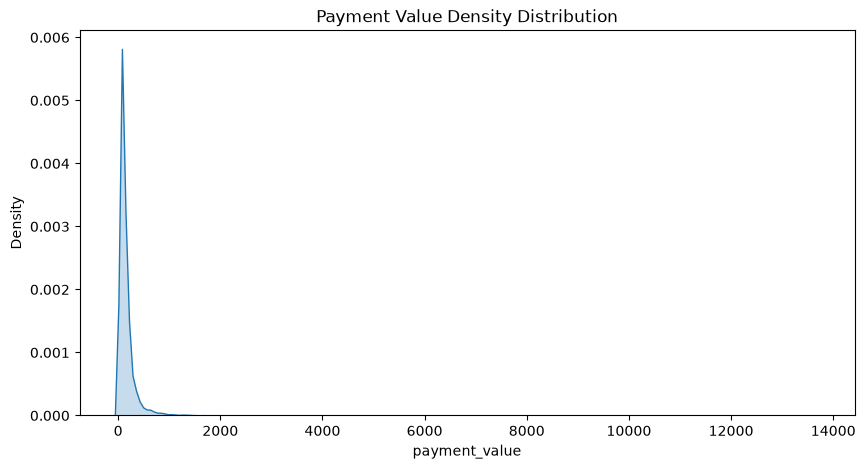

In [19]:
plt.figure(figsize=(10, 5))

sns.kdeplot(
    data=payments,
    x="payment_value",
    fill=True
)

plt.title("Payment Value Density Distribution")

plt.show()